<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/Restnet50-new/notebooks/resnet50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import sys
import json
import hashlib
import time
import random
import platform
import shutil
import subprocess
import gc

import numpy as np
import pandas as pd
import tensorflow as tf
import keras
import sklearn
import kagglehub
import matplotlib
import matplotlib.pyplot as plt

# Architecture-specific preprocessor for ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet50_preprocess_input

print("All imports completed successfully.")

All imports completed successfully.


In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
    determinism_status = "TensorFlow op determinism enabled"
except Exception as e:
    determinism_status = f"Could not enable op determinism: {e}"

print(f"Seed:        {SEED}")
print(f"Determinism: {determinism_status}")

Seed:        42
Determinism: TensorFlow op determinism enabled


In [3]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        gpu_name = subprocess.check_output(
            ['nvidia-smi', '--query-gpu=name', '--format=csv,noheader'],
            text=True,
        ).strip().splitlines()[0]
        nvidia_smi = subprocess.check_output(
            ['nvidia-smi', '--query-gpu=name,driver_version,memory.total', '--format=csv,noheader'],
            text=True,
        ).strip().splitlines()[0]
    except Exception:
        gpu_name = tf.config.experimental.get_device_details(gpus[0]).get('device_name', 'Unknown GPU')
        nvidia_smi = 'Unavailable'
else:
    gpu_name = 'No GPU detected'
    nvidia_smi = 'N/A'

environment_info = {
    'member': 3,
    'model': 'ResNet50',
    'python_version': sys.version,
    'platform': platform.platform(),
    'tensorflow_version': tf.__version__,
    'keras_version': keras.__version__,
    'numpy_version': np.__version__,
    'pandas_version': pd.__version__,
    'scikit_learn_version': sklearn.__version__,
    'kagglehub_version': getattr(kagglehub, '__version__', 'unknown'),
    'matplotlib_version': matplotlib.__version__,
    'gpu_name': gpu_name,
    'nvidia_smi': nvidia_smi,
    'seed': SEED,
    'determinism_status': determinism_status,
}

print('Environment Recorded:')
for k, v in environment_info.items():
    print(f'  {k:<22}: {v}')

Environment Recorded:
  member                : 3
  model                 : ResNet50
  python_version        : 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
  platform              : Linux-6.6.122+-x86_64-with-glibc2.39
  tensorflow_version    : 2.21.0
  keras_version         : 3.13.2
  numpy_version         : 2.1.3
  pandas_version        : 2.2.3
  scikit_learn_version  : 1.6.1
  kagglehub_version     : 1.0.2
  matplotlib_version    : 3.10.0
  gpu_name              : No GPU detected
  nvidia_smi            : N/A
  seed                  : 42
  determinism_status    : TensorFlow op determinism enabled


In [4]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
from pathlib import Path

# Folder layout expected inside Dataset:
#   Dataset/ga/correct, Dataset/ga/wrong, Dataset/ra/correct, ... (5 letters x correct/wrong)
PROJECT_DIR = Path("/content/drive/MyDrive/dataset")
DATA_DIR = Path("/content/drive/MyDrive/dataset")
SPLITS_DIR = PROJECT_DIR / "data" / "splits_10class"
RESULTS_DIR = PROJECT_DIR / "results_10class"
PLOTS_DIR = RESULTS_DIR / "plots"
METRICS_DIR = RESULTS_DIR / "metrics"
MODELS_DIR = PROJECT_DIR / "models_10class"
FINAL_MODEL_DIR = MODELS_DIR / "final"
CHECKPOINT_DIR = MODELS_DIR / "checkpoints"

for folder in [
    SPLITS_DIR, PLOTS_DIR, METRICS_DIR, FINAL_MODEL_DIR, CHECKPOINT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

## 1. Scan the dataset (`correct` / `wrong`)

Expected layout (inside `DATA_DIR`):
```
raw/
  correct/  img1.jpg, img2.png, ...
  wrong/    img1.jpg, ...
```
This cell lists every image, checks that it opens, removes exact duplicates (so the same image can't end up in both train and test), and builds a table of `path / label / class`.

In [6]:
import io
from PIL import Image

# Image settings
IMG_HEIGHT = 224          # ResNet50 standard input size
IMG_WIDTH  = 224
BATCH_SIZE = 32

LETTERS = ["ga", "ra", "ta", "u", "la"]          # folder names of the 5 letters
STATES  = ["correct", "wrong"]                   # sub-folder names inside each letter
CLASS_NAMES = [f"{l}_{s}" for l in LETTERS for s in STATES]   # 10 classes -> labels 0..9
CLASS_TO_ID = {c: i for i, c in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)
IMAGE_EXTS  = {".jpg", ".jpeg", ".png", ".bmp"}

if not DATA_DIR.exists():
    raise FileNotFoundError(f"DATA_DIR not found: {DATA_DIR}  -> check the path in the paths cell")

rows, corrupt = [], []
for letter in LETTERS:
    for state in STATES:
        cls = f"{letter}_{state}"
        cls_dir = DATA_DIR / letter / state
        if not cls_dir.is_dir():
            raise FileNotFoundError(
                f"Missing folder: {cls_dir}\nFolders found in DATA_DIR: {[p.name for p in DATA_DIR.iterdir()]}"
            )
        for p in sorted(cls_dir.rglob("*")):
            if p.suffix.lower() not in IMAGE_EXTS:
                continue
            try:
                data = p.read_bytes()
                Image.open(io.BytesIO(data)).verify()          # raises if the file is broken
                rows.append({"path": str(p), "label": CLASS_TO_ID[cls], "class": cls,
                             "letter": letter, "state": state,
                             "md5": hashlib.md5(data).hexdigest()})
            except Exception as e:
                corrupt.append((str(p), str(e)))

df = pd.DataFrame(rows)
print(f"Valid images found : {len(df)}")
print(f"Corrupt/unreadable : {len(corrupt)}")
for path, err in corrupt[:5]:
    print("   ", path, "->", err)

# Same image present in DIFFERENT folders = conflicting label -> remove all copies
n_labels_per_hash = df.groupby("md5")["label"].nunique()
conflict_hashes = n_labels_per_hash[n_labels_per_hash > 1].index
if len(conflict_hashes):
    print(f"WARNING: {len(conflict_hashes)} image(s) appear in more than one folder -> removed")
    df = df[~df["md5"].isin(conflict_hashes)]

# Exact duplicates inside the same class -> keep one copy
n_before = len(df)
df = df.drop_duplicates("md5", keep="first").reset_index(drop=True)
print(f"Exact duplicates removed: {n_before - len(df)}")

print("\nImages per class:")
print(df["class"].value_counts().reindex(CLASS_NAMES).to_string())

Valid images found : 1001
Corrupt/unreadable : 0
Exact duplicates removed: 2

Images per class:
class
ga_correct    113
ga_wrong       88
ra_correct    125
ra_wrong       74
ta_correct     79
ta_wrong      121
u_correct      65
u_wrong       135
la_correct     63
la_wrong      136


## 2. Train / validation / test split (70 / 15 / 15, stratified)

The split is saved as CSV files so every experiment (and every team member) uses exactly the same images.

In [7]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    part.to_csv(SPLITS_DIR / f"{name}.csv", index=False)
    counts = part["class"].value_counts().to_dict()
    print(f"{name:<5}: {len(part):>5} images  {counts}")

train:   699 images  {'la_wrong': 95, 'u_wrong': 94, 'ra_correct': 87, 'ta_wrong': 85, 'ga_correct': 79, 'ga_wrong': 62, 'ta_correct': 55, 'ra_wrong': 52, 'u_correct': 46, 'la_correct': 44}
val  :   150 images  {'la_wrong': 21, 'u_wrong': 21, 'ra_correct': 19, 'ta_wrong': 18, 'ga_correct': 17, 'ga_wrong': 13, 'ta_correct': 12, 'ra_wrong': 11, 'u_correct': 9, 'la_correct': 9}
test :   150 images  {'u_wrong': 20, 'la_wrong': 20, 'ra_correct': 19, 'ta_wrong': 18, 'ga_correct': 17, 'ga_wrong': 13, 'ta_correct': 12, 'ra_wrong': 11, 'u_correct': 10, 'la_correct': 10}


## 3. Preprocessing: same size + pure black & white

Steps for every image:
1. Decode (works for JPG / PNG / BMP)
2. Convert to grayscale
3. Pick a threshold (Otsu = automatic per image, or a fixed value)
4. Resize to 224x224 **keeping the aspect ratio** (the letter shape is not stretched; padding is white)
5. Threshold into pure black (0) and white (255)
6. Copy the 1 channel into 3 channels and apply ResNet50 `preprocess_input`

The black/white result is cached in memory (uint8, 1 channel) so only the first epoch reads from Drive.

In [8]:
USE_OTSU        = True     # True: automatic threshold per image | False: use FIXED_THRESHOLD
FIXED_THRESHOLD = 127.0

def otsu_threshold(gray):
    """gray: float32 tensor with values 0-255. Returns Otsu's threshold as a scalar."""
    hist  = tf.cast(tf.histogram_fixed_width(gray, [0.0, 256.0], nbins=256), tf.float32)
    bins  = tf.range(256, dtype=tf.float32)
    w_bg  = tf.cumsum(hist)                         # pixels at or below each level
    w_fg  = tf.reduce_sum(hist) - w_bg              # pixels above each level
    s_all = tf.reduce_sum(hist * bins)
    s_bg  = tf.cumsum(hist * bins)
    m_bg  = s_bg / tf.maximum(w_bg, 1.0)
    m_fg  = (s_all - s_bg) / tf.maximum(w_fg, 1.0)
    between_class_variance = w_bg * w_fg * tf.square(m_bg - m_fg)
    return tf.cast(tf.argmax(between_class_variance), tf.float32)

def load_and_binarize(file_path):
    """Image path -> uint8 tensor [224, 224, 1] containing only 0 (black) and 255 (white)."""
    img = tf.io.decode_image(tf.io.read_file(file_path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])

    gray = tf.image.rgb_to_grayscale(tf.cast(img, tf.float32))        # [H, W, 1], 0-255
    thr  = otsu_threshold(gray) if USE_OTSU else FIXED_THRESHOLD       # threshold from the original image

    # Resize with aspect ratio kept. resize_with_pad pads with 0, so invert -> resize -> invert back
    # to make the padding white instead of black.
    inverted = 255.0 - gray
    inverted = tf.image.resize_with_pad(inverted, IMG_HEIGHT, IMG_WIDTH, antialias=True)
    gray     = 255.0 - inverted

    bw = tf.where(gray > thr, 255.0, 0.0)                              # pure black & white
    return tf.cast(bw, tf.uint8)

def to_resnet_input(bw, label):
    """[224, 224, 1] uint8 B&W -> [224, 224, 3] float32 in ResNet50's expected input format."""
    x = tf.tile(tf.cast(bw, tf.float32), [1, 1, 3])
    return resnet50_preprocess_input(x), label

def make_dataset(df_part, training):
    paths  = df_part["path"].tolist()
    labels = df_part["label"].astype("int32").tolist()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(lambda p, y: (load_and_binarize(p), y), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.cache()                                   # keep the small B&W images in RAM after epoch 1
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(to_resnet_input, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

## 4. Visual check

Look at a few results before training. Letters should be clearly black on white, not broken or filled in. If they look wrong, try `USE_OTSU = False` and change `FIXED_THRESHOLD`.

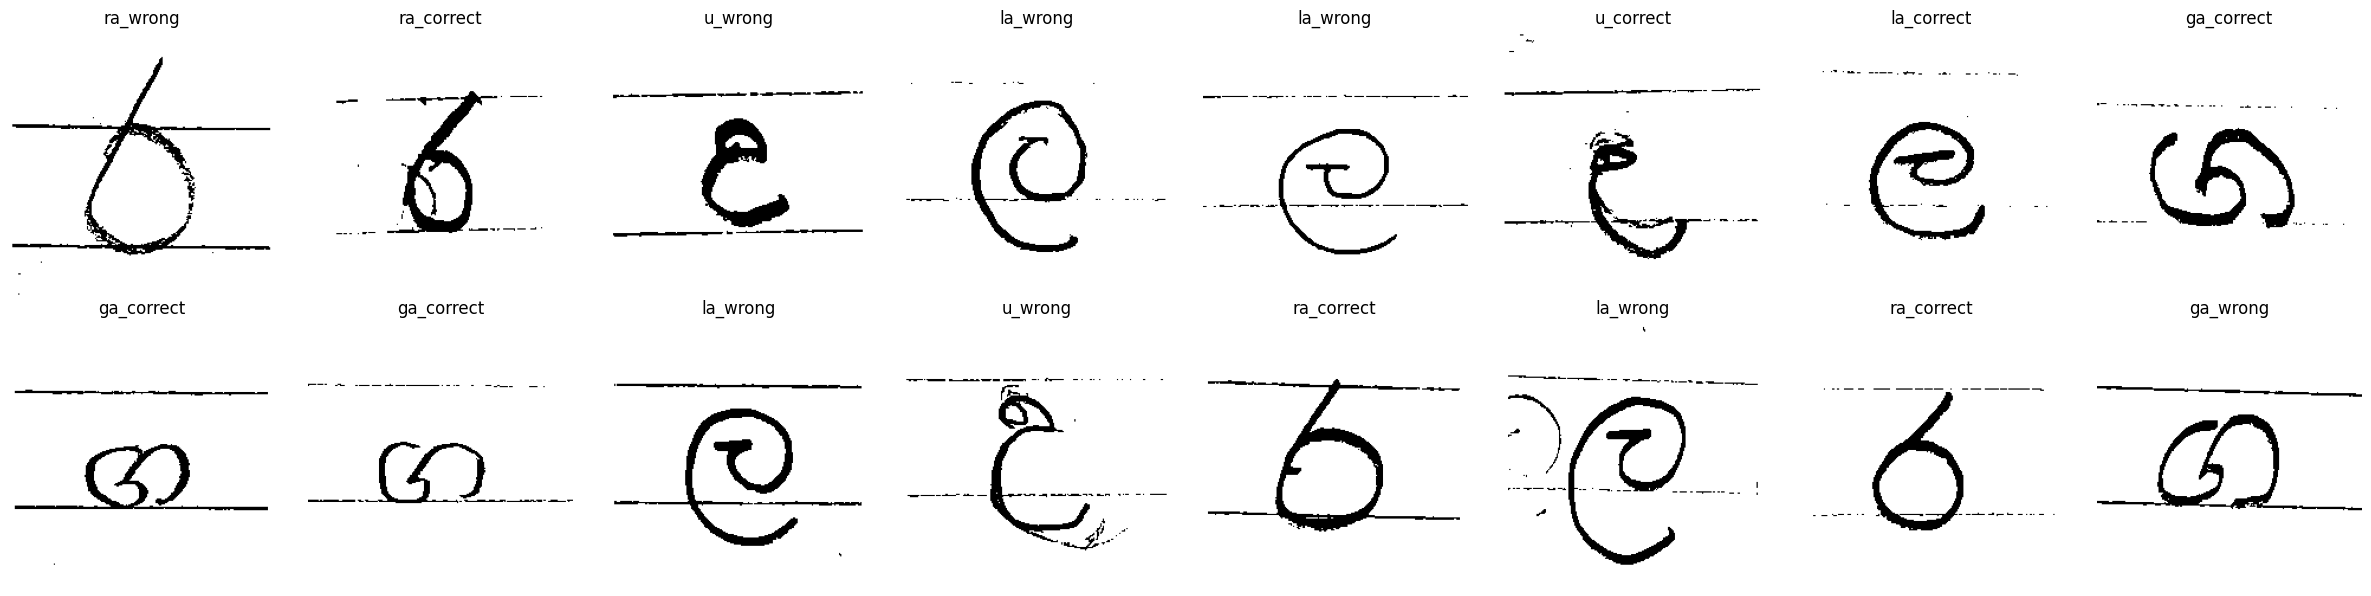

In [9]:
def show_samples(df_part, n=16):
    n = min(n, len(df_part))
    sample = df_part.sample(n, random_state=SEED)
    cols = max(n // 2, 1)
    fig, axes = plt.subplots(2, cols, figsize=(3 * cols, 6))
    for ax, (_, r) in zip(np.ravel(axes), sample.iterrows()):
        bw = load_and_binarize(r["path"]).numpy().squeeze()
        ax.imshow(bw, cmap="gray", vmin=0, vmax=255)
        ax.set_title(r["class"])
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(train_df)

## 5. Build the datasets

In [10]:
train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df,   training=False)
test_ds  = make_dataset(test_df,  training=False)

# Sanity check on one batch
x, y = next(iter(train_ds))
print("Batch images :", x.shape, x.dtype)
print("Batch labels :", y.shape, y.dtype)
print(f"Value range  : {float(tf.reduce_min(x)):.1f} to {float(tf.reduce_max(x)):.1f}")

# Class weights (helps if one class has far fewer images)
from sklearn.utils.class_weight import compute_class_weight
w = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label"].values)
class_weight = {i: float(w[i]) for i in range(NUM_CLASSES)}
print("Class weights:", class_weight, "| labels:", dict(enumerate(CLASS_NAMES)))

Batch images : (32, 224, 224, 3) <dtype: 'float32'>
Batch labels : (32,) <dtype: 'int32'>
Value range  : -123.7 to 151.1
Class weights: {0: 0.8848101265822785, 1: 1.1274193548387097, 2: 0.803448275862069, 3: 1.3442307692307693, 4: 1.270909090909091, 5: 0.8223529411764706, 6: 1.5195652173913043, 7: 0.7436170212765958, 8: 1.5886363636363636, 9: 0.7357894736842105} | labels: {0: 'ga_correct', 1: 'ga_wrong', 2: 'ra_correct', 3: 'ra_wrong', 4: 'ta_correct', 5: 'ta_wrong', 6: 'u_correct', 7: 'u_wrong', 8: 'la_correct', 9: 'la_wrong'}


## 6. Build the ResNet50 model

Paste these cells **below your last cell** (they use `train_ds`, `val_ds`, `class_weight`, `CLASS_NAMES`, `CHECKPOINT_DIR`, `FINAL_MODEL_DIR`, `METRICS_DIR`, `PLOTS_DIR` from the earlier cells).

Before running: Runtime → Change runtime type → **T4 GPU**.

Plan (standard transfer learning):
1. **Stage 1:** ResNet50 pretrained on ImageNet is frozen, only the new classifier head is trained.
2. **Stage 2:** the last layers of ResNet50 are unfrozen and fine-tuned with a very small learning rate.

The model outputs one number: the probability of **class 1** (`CLASS_NAMES[1]`, which is `Wrong`). Precision and recall below are therefore for the `Wrong` class.

In [11]:
from tensorflow.keras import layers, models, optimizers, callbacks, metrics

gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus if gpus else "NONE - switch the runtime to a T4 GPU, training on CPU is extremely slow")

# ---------------- Model / training settings ----------------
WEIGHTS          = "imagenet"   # pretrained weights
DROPOUT          = 0.6
USE_AUGMENTATION = True         # light shift/zoom only (no flips, no rotation: they can change a letter's meaning)

EPOCHS_HEAD      = 15           # stage 1 (early stopping may end it sooner)
EPOCHS_FINE      = 30           # stage 2 (early stopping may end it sooner)
LR_HEAD          = 0.0003
LR_FINE          = 0.0001
UNFREEZE_LAST_N  = 175           # how many of ResNet50's last layers to fine-tune in stage 2

GPUs: NONE - switch the runtime to a T4 GPU, training on CPU is extremely slow


In [12]:
def build_resnet50(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), dropout=DROPOUT, augment=USE_AUGMENTATION):
    # include_top=False removes the 1000-class ImageNet classifier, we add our own head
    base = tf.keras.applications.ResNet50(
        include_top=False, weights=WEIGHTS, input_shape=input_shape)
    base.trainable = False                       # stage 1: backbone frozen

    inputs = layers.Input(shape=input_shape, name="image")   # already ResNet50-preprocessed by the data pipeline
    x = inputs
    if augment:
        x = layers.RandomTranslation(0.05, 0.05, fill_mode="nearest")(x)
        x = layers.RandomZoom(0.05, fill_mode="nearest")(x)

    x = base(x, training=False)                  # keeps BatchNorm in inference mode (important for fine-tuning)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="class_probs")(x)

    model = models.Model(inputs, outputs, name="resnet50_letter_10class")
    return model, base


def compile_model(model, lr):
    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",   # labels are integers 0..9
        metrics=["accuracy"],
    )


def make_callbacks(stage):
    return [
        callbacks.ModelCheckpoint(
            str(CHECKPOINT_DIR / f"resnet50_{stage}_best.keras"),
            monitor="val_loss", save_best_only=True, verbose=1),
        callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
    ]


def count_params(model):
    trainable = int(sum(np.prod(v.shape) for v in model.trainable_weights))
    total = int(model.count_params())
    return trainable, total


model, base = build_resnet50()
compile_model(model, LR_HEAD)

trainable, total = count_params(model)
print(f"Stage 1 | trainable params: {trainable:,} of {total:,}")
print("Output classes:", dict(enumerate(CLASS_NAMES)))
model.summary(show_trainable=True)

Stage 1 | trainable params: 20,490 of 23,608,202
Output classes: {0: 'ga_correct', 1: 'ga_wrong', 2: 'ra_correct', 3: 'ra_wrong', 4: 'ta_correct', 5: 'ta_wrong', 6: 'u_correct', 7: 'u_wrong', 8: 'la_correct', 9: 'la_wrong'}


Model: "resnet50_letter_10class"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ image (InputLayer)          │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ random_translation          │ (None, 224, 224, 3)   │          0 │   -   │
│ (RandomTranslation)         │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ random_zoom (RandomZoom)    │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ resnet50 (Functional)       │ (None, 7, 7, 2048)    │ 23,587,712 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 2048)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 2048)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ class_probs (Dense)         │ (None, 10)            │     20,490 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 23,608,202 (90.06 MB)

 Trainable params: 20,490 (80.04 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

## 7. Stage 1 - train the classifier head (ResNet50 frozen)

In [13]:
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    class_weight=class_weight,
    callbacks=make_callbacks("head"),
)

Epoch 1/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.1010 - loss: 3.1904
Epoch 1: val_loss improved from None to 2.40926, saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/resnet50_head_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/resnet50_head_best.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 177s 8s/step - accuracy: 0.0858 - loss: 3.2149 - val_accuracy: 0.1333 - val_loss: 2.4093 - learning_rate: 3.0000e-04
Epoch 2/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.1406 - loss: 2.8814
Epoch 2: val_loss improved from 2.40926 to 2.03925, saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/resnet50_head_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/resnet50_head_best.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 196s 7s/step - accuracy: 0.1516 - loss: 2.8260 - val_accuracy: 0.3200 - val_loss: 2.0393 - learning_rate: 3.0000e-04
Epoch 3/15


## 8. Stage 2 - fine-tune the last ResNet50 layers

Only the last `UNFREEZE_LAST_N` layers are unfrozen. BatchNorm layers stay frozen, and the learning rate is 100x smaller so the pretrained features are adjusted gently instead of destroyed.

In [14]:
base.trainable = True
for layer in base.layers[:-UNFREEZE_LAST_N]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

compile_model(model, LR_FINE)          # must re-compile after changing trainable flags

trainable, total = count_params(model)
print(f"Stage 2 | trainable params: {trainable:,} of {total:,}")

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    class_weight=class_weight,
    callbacks=make_callbacks("finetune"),
)

Stage 2 | trainable params: 23,501,962 of 23,608,202
Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 19s/step - accuracy: 0.3574 - loss: 3.2915 
Epoch 1: val_loss improved from None to 0.83080, saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/resnet50_finetune_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/resnet50_finetune_best.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 481s 21s/step - accuracy: 0.3691 - loss: 2.1335 - val_accuracy: 0.5467 - val_loss: 0.8308 - learning_rate: 1.0000e-04
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 19s/step - accuracy: 0.5299 - loss: 0.9636 
Epoch 2: val_loss improved from 0.83080 to 0.59508, saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/resnet50_finetune_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/resnet50_finetune_best.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 479s 22s/step - accuracy: 0.5465 - loss: 0.9085 - val_

## 9. Training curves + save

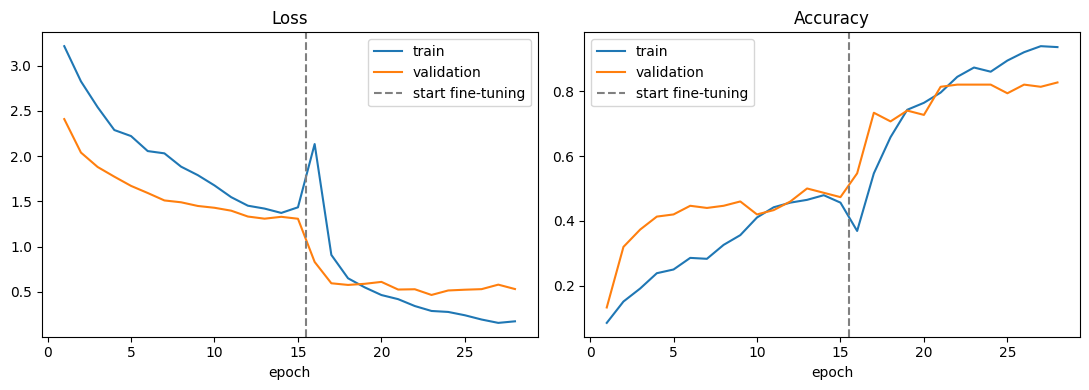

Best validation loss 0.4661 at epoch 23 (finetune) | val acc 0.8200
Model saved to: /content/drive/MyDrive/dataset/models_10class/final/resnet50_letter_10class.keras


In [15]:
# Join both stages into one history
history_all = {k: history_head.history[k] + history_fine.history[k] for k in history_head.history}
hist_df = pd.DataFrame(history_all)
hist_df.insert(0, "epoch", range(1, len(hist_df) + 1))
hist_df.insert(1, "stage", ["head"] * len(history_head.history["loss"]) + ["finetune"] * len(history_fine.history["loss"]))
hist_df.to_csv(METRICS_DIR / "resnet50_training_history.csv", index=False)

split_at = len(history_head.history["loss"]) + 0.5      # boundary between stage 1 and stage 2
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (key, title) in zip(axes, [("loss", "Loss"), ("accuracy", "Accuracy")]):
    ax.plot(hist_df["epoch"], hist_df[key], label="train")
    ax.plot(hist_df["epoch"], hist_df[f"val_{key}"], label="validation")
    ax.axvline(split_at, color="gray", linestyle="--", label="start fine-tuning")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "resnet50_training_curves.png", dpi=150)
plt.show()

best_row = hist_df.loc[hist_df["val_loss"].idxmin()]
print(f"Best validation loss {best_row['val_loss']:.4f} at epoch {int(best_row['epoch'])} "
      f"({best_row['stage']}) | val acc {best_row['val_accuracy']:.4f}")

model.save(FINAL_MODEL_DIR / "resnet50_letter_10class.keras")
print("Model saved to:", FINAL_MODEL_DIR / "resnet50_letter_10class.keras")
# Save the class order: the app needs this exact list to turn model outputs into names
with open(FINAL_MODEL_DIR / "class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f)

## 10. Model evaluation

Paste these cells below your last cell. They use `model`, `train_ds`, `val_ds`, `test_ds`, `test_df`, `CLASS_NAMES`, `METRICS_DIR`, `PLOTS_DIR` and `load_and_binarize` from the earlier cells.

**Positive class = class 1 = `Wrong`.** Precision, recall and F1 below are for detecting `Wrong` unless a row says macro or weighted.

In [16]:
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
)

def predict_dataset(ds):
    """Returns (true labels, probability matrix [N, 10]) in dataset order."""
    labels, probs = [], []
    for x, y in ds:
        probs.append(np.asarray(model.predict_on_batch(x)))
        labels.append(y.numpy())
    return np.concatenate(labels), np.concatenate(probs)

# class id -> letter id / correct-or-wrong, so we can score the "real app" decision
LETTER_OF  = np.array([i // 2 for i in range(NUM_CLASSES)])      # 0..4
IS_CORRECT = np.array([i % 2 == 0 for i in range(NUM_CLASSES)])  # even ids are *_correct

def compute_metrics(y_true, probs):
    y_pred = probs.argmax(axis=1)
    # What the app really needs, split in two questions:
    letter_acc = accuracy_score(LETTER_OF[y_true], LETTER_OF[y_pred])        # right letter identified?
    quality_acc = accuracy_score(IS_CORRECT[y_true], IS_CORRECT[y_pred])     # correct/wrong judged right?
    return {
        "samples":           int(len(y_true)),
        "accuracy_10class":  float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "f1_macro":          float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "letter_accuracy":   float(letter_acc),
        "correct_wrong_accuracy": float(quality_acc),
    }

### Train vs validation vs test

If train is much better than validation/test, the model is overfitting.

In [17]:
raw, results = {}, {}
for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    y_t, p = predict_dataset(ds)
    raw[name] = (y_t, p)
    results[name] = compute_metrics(y_t, p)

summary = pd.DataFrame(results).T
summary["samples"] = summary["samples"].astype(int)
display(summary.round(4))
summary.to_csv(METRICS_DIR / "resnet50_10class_metrics_all_splits.csv")


,samples,accuracy_10class,balanced_accuracy,f1_macro,letter_accuracy,correct_wrong_accuracy
train,699,0.9099,0.9047,0.9038,1.0000,0.9099
val,150,0.8200,0.8187,0.7999,0.9933,0.8267
test,150,0.7933,0.7906,0.7796,1.0000,0.7933


### Test set: full classification report (threshold 0.5)

In [18]:
y_true, probs = raw["test"]
y_pred = probs.argmax(axis=1)

print(classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                            target_names=CLASS_NAMES, digits=3, zero_division=0))
m = results["test"]
for k, v in m.items():
    print(f"{k:<24}: {v}")

              precision    recall  f1-score   support

  ga_correct      0.667     0.824     0.737        17
    ga_wrong      0.667     0.462     0.545        13
  ra_correct      0.944     0.895     0.919        19
    ra_wrong      0.833     0.909     0.870        11
  ta_correct      0.550     0.917     0.688        12
    ta_wrong      0.900     0.500     0.643        18
   u_correct      0.778     0.700     0.737        10
     u_wrong      0.857     0.900     0.878        20
  la_correct      0.818     0.900     0.857        10
    la_wrong      0.947     0.900     0.923        20

    accuracy                          0.793       150
   macro avg      0.796     0.791     0.780       150
weighted avg      0.813     0.793     0.790       150

samples                 : 150
accuracy_10class        : 0.7933333333333333
balanced_accuracy       : 0.7905562291166006
f1_macro                : 0.7796248595855813
letter_accuracy         : 1.0
correct_wrong_accuracy  : 0.7933333333333333


### Confusion matrix

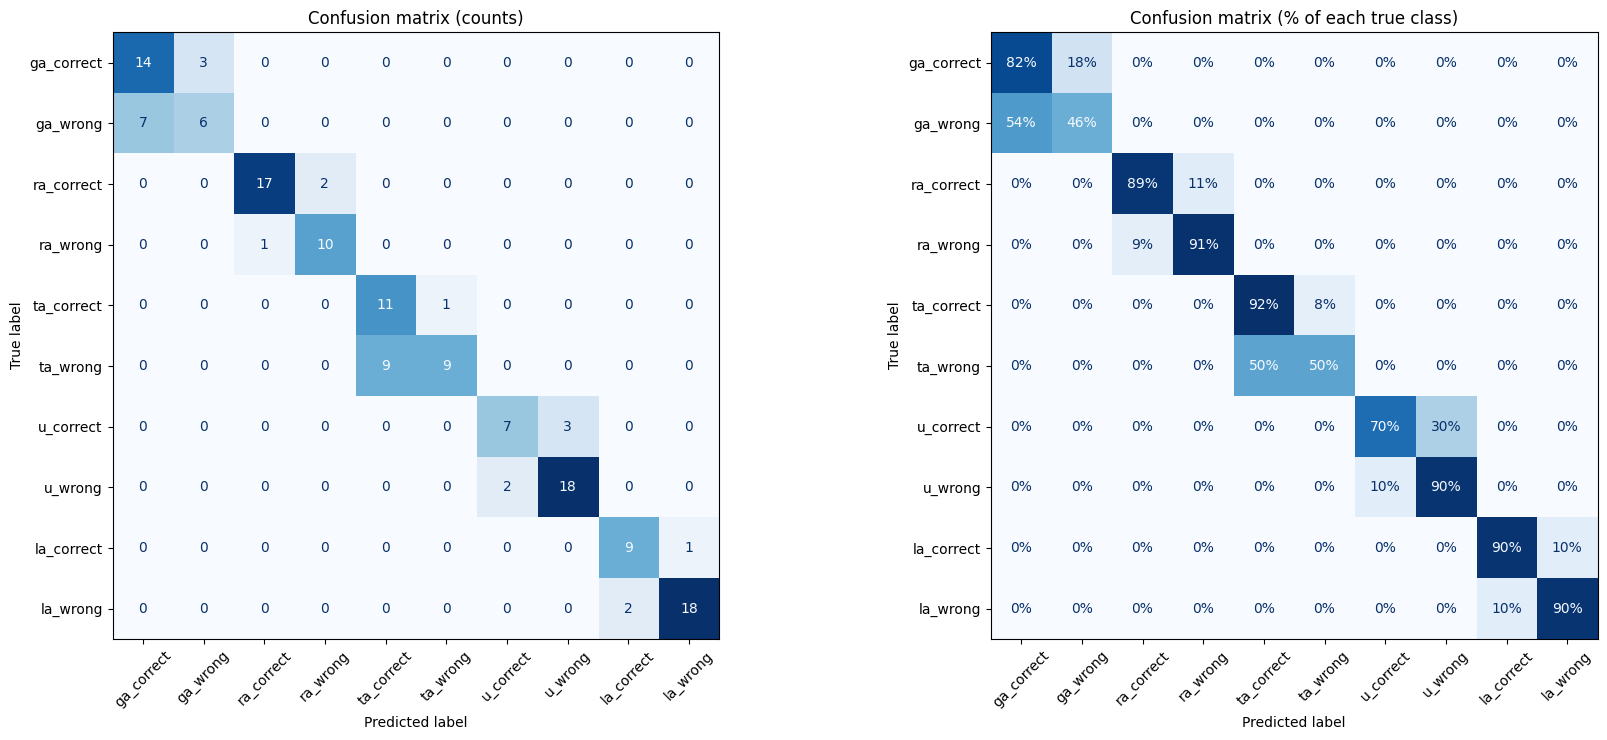

In [19]:
cm      = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
cm_norm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)), normalize="true")

fig, ax = plt.subplots(1, 2, figsize=(18, 7.5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax[0], cmap="Blues", colorbar=False, xticks_rotation=45)
ax[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay(cm_norm, display_labels=CLASS_NAMES).plot(
    ax=ax[1], cmap="Blues", colorbar=False, values_format=".0%", xticks_rotation=45)
ax[1].set_title("Confusion matrix (% of each true class)")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "resnet50_10class_confusion_matrix.png", dpi=150)
plt.show()

In [20]:
# ---------- The real app scenario ----------
# The app ASKS for a letter. Answer is "Correct" only if the model predicts "<asked>_correct".
def app_decision(probs_row, asked_letter_id):
    return int(probs_row.argmax() == asked_letter_id * 2)     # 1 = app says Correct

# Test 1: student writes the ASKED letter (the normal case)
true_letter = LETTER_OF[y_true]
app_says = np.array([app_decision(p, l) for p, l in zip(probs, true_letter)])
should_be = IS_CORRECT[y_true].astype(int)
print(f"Test 1 - student writes the asked letter: app is right {np.mean(app_says == should_be):.1%} of the time")

# Test 2: student writes a DIFFERENT letter than asked (always must be Wrong)
fooled, total = 0, 0
for p, l in zip(probs, true_letter):
    for asked in range(len(LETTERS)):
        if asked == l:
            continue
        total += 1
        fooled += app_decision(p, asked)          # app wrongly says Correct
print(f"Test 2 - student writes another letter: app wrongly says Correct {fooled/total:.1%} of the time "
      f"({fooled} of {total})")

Test 1 - student writes the asked letter: app is right 79.3% of the time
Test 2 - student writes another letter: app wrongly says Correct 0.0% of the time (0 of 600)


/tmp/ipykernel_16181/779872363.py:11: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(PLOTS_DIR / "resnet50_10class_confidence.png", dpi=150)


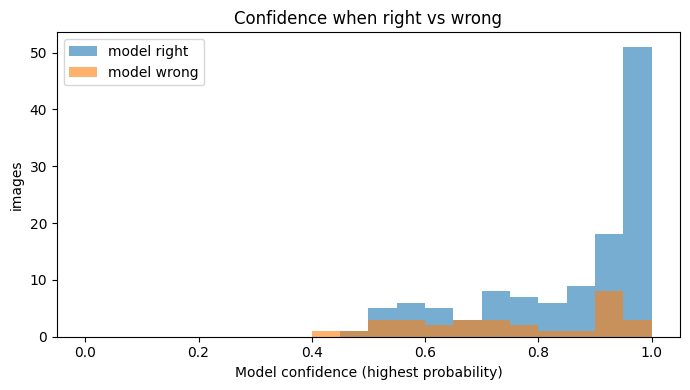

confidence >= 0.4: answered 100% of images, accuracy on those 79.3%
confidence >= 0.5: answered 98% of images, accuracy on those 80.3%
confidence >= 0.6: answered 87% of images, accuracy on those 82.3%
confidence >= 0.7: answered 78% of images, accuracy on those 84.6%
confidence >= 0.8: answered 65% of images, accuracy on those 86.6%


In [21]:
# Confidence: how sure is the model when it is right vs wrong? Use this to choose a "try again" limit.
conf = probs.max(axis=1)
right = (y_pred == y_true)

plt.figure(figsize=(7, 4))
plt.hist(conf[right],  bins=20, range=(0, 1), alpha=0.6, label="model right")
plt.hist(conf[~right], bins=20, range=(0, 1), alpha=0.6, label="model wrong")
plt.xlabel("Model confidence (highest probability)"); plt.ylabel("images"); plt.legend()
plt.title("Confidence when right vs wrong")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "resnet50_10class_confidence.png", dpi=150)
plt.show()

for t in [0.4, 0.5, 0.6, 0.7, 0.8]:
    keep = conf >= t
    print(f"confidence >= {t:.1f}: answered {keep.mean():.0%} of images, accuracy on those {right[keep].mean():.1%}")

### Inspect misclassified test images (most confident mistakes first)

These show what the model gets wrong, which is useful for error analysis in the report.

Misclassified test images: 31 of 150


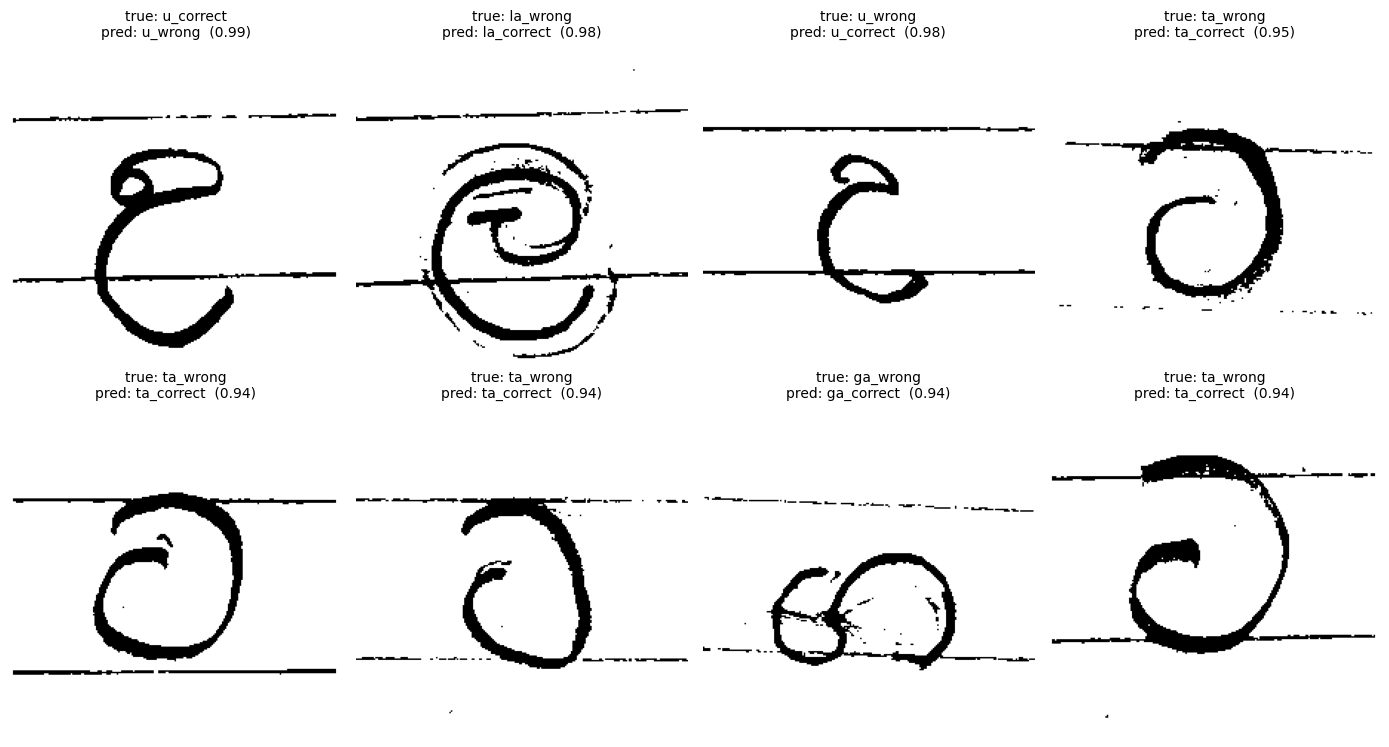

In [22]:
assert np.array_equal(y_true, test_df["label"].values), "test_ds order does not match test_df"

wrong_idx = np.where(y_pred != y_true)[0]
print(f"Misclassified test images: {len(wrong_idx)} of {len(y_true)}")

if len(wrong_idx):
    err_conf = probs[wrong_idx, y_pred[wrong_idx]]          # most confident mistakes first
    wrong_idx = wrong_idx[np.argsort(-err_conf)]
    show = wrong_idx[:8]

    fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), show):
        bw = load_and_binarize(test_df.iloc[i]["path"]).numpy().squeeze()
        ax.imshow(bw, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"true: {CLASS_NAMES[y_true[i]]}\npred: {CLASS_NAMES[y_pred[i]]}  ({probs[i, y_pred[i]]:.2f})",
                     fontsize=10)
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / "resnet50_10class_misclassified.png", dpi=150)
    plt.show()

### Save the evaluation results and predictions

In [23]:
with open(METRICS_DIR / "resnet50_10class_test_metrics.json", "w") as f:
    json.dump({"test": results["test"], "class_names": CLASS_NAMES}, f, indent=2)

pred_df = test_df.drop(columns=["md5"], errors="ignore").copy()
for i, c in enumerate(CLASS_NAMES):
    pred_df["prob_" + c] = probs[:, i]
pred_df["pred_label"] = y_pred
pred_df["pred_class"] = [CLASS_NAMES[i] for i in y_pred]
pred_df["is_correct"] = (y_pred == y_true)
pred_df.to_csv(METRICS_DIR / "resnet50_10class_test_predictions.csv", index=False)
print("Saved to", METRICS_DIR)

Saved to /content/drive/MyDrive/dataset/results_10class/metrics


### Download the trained model

In [24]:
from google.colab import files
files.download(str(FINAL_MODEL_DIR / "resnet50_letter_10class.keras"))
files.download(str(FINAL_MODEL_DIR / "class_names.json"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
# ================= APP-SIDE LOGIC =================
# Use this function inside app. It needs: the image path and the letter the app asked for.
MIN_CONFIDENCE = 0.5      # below this the model is unsure -> ask the student to try again

def check_letter(image_path, asked_letter):
    """asked_letter: one of 'ga','ra','ta','u','la'. Returns (verdict, details)."""
    bw = load_and_binarize(image_path)
    x, _ = to_resnet_input(bw, 0)
    probs = model.predict(x[None, ...], verbose=0)[0]

    best = int(probs.argmax())
    pred_class = CLASS_NAMES[best]
    confidence = float(probs[best])
    pred_letter, pred_state = pred_class.split("_")

    if confidence < MIN_CONFIDENCE:
        verdict = "Try again"
    elif pred_letter != asked_letter:
        verdict = "Wrong"          # a different letter was written
    elif pred_state == "correct":
        verdict = "Correct"
    else:
        verdict = "Wrong"          # right letter, written badly
    return verdict, {"model_saw": pred_class, "confidence": round(confidence, 3)}

# Example (change the path):
# print(check_letter(test_df.iloc[0]["path"], "ga"))